<a href="https://colab.research.google.com/github/dairxp/Py-Colab-ALD/blob/main/07_Deep_Learning_Lenguaje_de_senias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Lectura de los datos

Origen de Datos: https://www.kaggle.com/datamunge/sign-language-mnist

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv('/content/drive/MyDrive/Machine Learning/Data/sign_mnist_train.csv')
test = pd.read_csv('/content/drive/MyDrive/Machine Learning/Data/sign_mnist_test.csv')

In [ ]:
print("El conjunto de datos tiene {} filas y {} columnas".format(train.shape[0],train.shape[1]))
train.head()

El conjunto de datos tiene 27455 filas y 785 columnas


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [ ]:
print("El conjunto de datos tiene {} filas y {} columnas".format(test.shape[0],test.shape[1]))
test.head()

El conjunto de datos tiene 7172 filas y 785 columnas


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,6,149,149,150,150,150,151,151,150,151,...,138,148,127,89,82,96,106,112,120,107
1,5,126,128,131,132,133,134,135,135,136,...,47,104,194,183,186,184,184,184,182,180
2,10,85,88,92,96,105,123,135,143,147,...,68,166,242,227,230,227,226,225,224,222
3,0,203,205,207,206,207,209,210,209,210,...,154,248,247,248,253,236,230,240,253,255
4,3,188,191,193,195,199,201,202,203,203,...,26,40,64,48,29,46,49,46,46,53


In [ ]:
y_train = train.label
x_train = train.drop("label",axis=1) / 255.0

y_test = test.label
x_test = test.drop("label",axis=1) / 255.0

In [ ]:
abc = [chr(65+i) for i in np.unique(y_test)]
print(abc)

['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


In [ ]:
letters_map = dict(zip(np.unique(y_test), range(len(np.unique(y_test)))))
letters_map

{np.int64(0): 0,
 np.int64(1): 1,
 np.int64(2): 2,
 np.int64(3): 3,
 np.int64(4): 4,
 np.int64(5): 5,
 np.int64(6): 6,
 np.int64(7): 7,
 np.int64(8): 8,
 np.int64(10): 9,
 np.int64(11): 10,
 np.int64(12): 11,
 np.int64(13): 12,
 np.int64(14): 13,
 np.int64(15): 14,
 np.int64(16): 15,
 np.int64(17): 16,
 np.int64(18): 17,
 np.int64(19): 18,
 np.int64(20): 19,
 np.int64(21): 20,
 np.int64(22): 21,
 np.int64(23): 22,
 np.int64(24): 23}

In [ ]:
y_train = y_train.replace(letters_map).values
y_test = y_test.replace(letters_map).values

In [ ]:
x_train = x_train.values.reshape((-1,28,28,1))
x_test = x_test.values.reshape((-1,28,28,1))

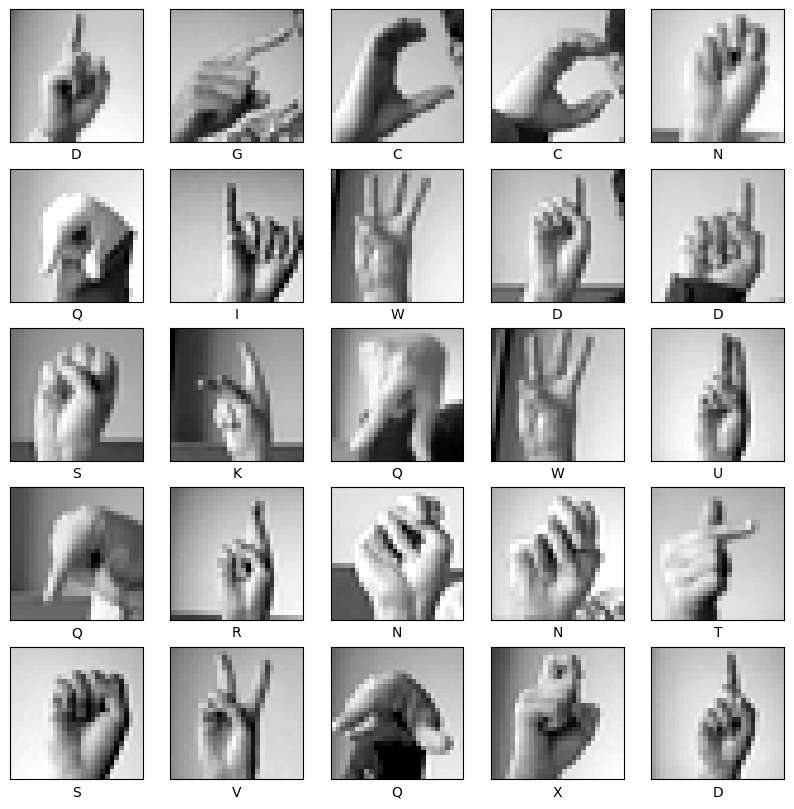

In [ ]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    number = x_train[i].reshape(28,28)
    plt.imshow(number, cmap=plt.cm.gray)
    # A la letra 65
    plt.xlabel(abc[y_train[i]])
plt.show()

##**Construyendo y entrenando la NN 1ra Forma**

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import datasets, layers, models

model = models.Sequential()
model.add(layers.Conv2D(filters = 64,
                        kernel_size = (4, 4),
                        activation='relu',
                        padding="same",
                        input_shape=(28,28,1,)))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.MaxPooling2D(pool_size = (2, 2)))

model.add(layers.Conv2D(filters = 64,
                        kernel_size = (4, 4),
                        activation='relu',
                        padding="same"))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.MaxPooling2D(pool_size = (2, 2)))

model.add(layers.Conv2D(filters = 64,
                        kernel_size = (4, 4),
                        activation='relu',
                        padding="same"))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.MaxPooling2D(pool_size = (2, 2)))

model.add(layers.Flatten())
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.Dense(24, activation='softmax'))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 64)       │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,240 (817.34 KB)

 Trainable params: 209,240 (817.34 KB)

 Non-trainable params: 0 (0.00 B)

##2da Forma

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import datasets, layers, models

model = models.Sequential()
model.add(layers.Conv2D(filters = 64,
                        kernel_size = (4, 4),
                        activation='tanh',
                        padding="same",
                        input_shape=(28,28,1,)))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.MaxPooling2D(pool_size = (2, 2)))

model.add(layers.Conv2D(filters = 64,
                        kernel_size = (4, 4),
                        activation='tanh',
                        padding="same"))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.MaxPooling2D(pool_size = (2, 2)))

model.add(layers.Conv2D(filters = 64,
                        kernel_size = (4, 4),
                        activation='relu',
                        padding="same"))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.MaxPooling2D(pool_size = (2, 2)))

model.add(layers.Flatten())
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.Dense(24, activation='softmax'))
model.summary()

##3ra Forma

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import datasets, layers, models

model = models.Sequential()
model.add(layers.Conv2D(filters = 64,
                        kernel_size = (4, 4),
                        activation='tanh',
                        padding="same",
                        input_shape=(28,28,1,)))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.MaxPooling2D(pool_size = (2, 2)))

model.add(layers.Conv2D(filters = 64,
                        kernel_size = (4, 4),
                        activation='tanh',
                        padding="same"))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.MaxPooling2D(pool_size = (2, 2)))

model.add(layers.Conv2D(filters = 64,
                        kernel_size = (4, 4),
                        activation='relu',
                        padding="same"))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.MaxPooling2D(pool_size = (2, 2)))

model.add(layers.Flatten())
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.Dense(24, activation='softmax'))
model.summary()

##4ta Forma

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train,
          validation_data = (x_test, y_test),
          epochs=10,
          batch_size = 100);

Epoch 1/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 17s 30ms/step - accuracy: 0.1784 - loss: 2.7010 - val_accuracy: 0.7561 - val_loss: 1.4397
Epoch 2/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.7374 - loss: 0.7489 - val_accuracy: 0.8859 - val_loss: 0.7865
Epoch 3/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8815 - loss: 0.3373 - val_accuracy: 0.9438 - val_loss: 0.4944
Epoch 4/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9315 - loss: 0.1953 - val_accuracy: 0.9504 - val_loss: 0.3327
Epoch 5/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9576 - loss: 0.1293 - val_accuracy: 0.9587 - val_loss: 0.2914
Epoch 6/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9682 - loss: 0.1028 - val_accuracy: 0.9670 - val_loss: 0.2046
Epoch 7/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9755 - loss: 0.0710 - val_accuracy: 0.9752 - val_loss: 0.1806
Epoch 8/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9811 - loss: 0.0546 - val_accuracy:

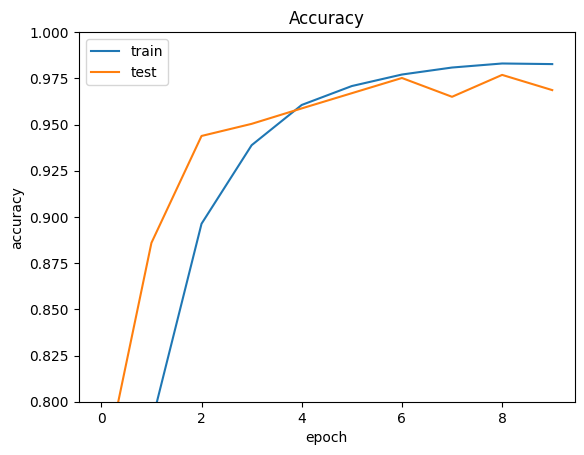

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.ylim(0.80, 1)
plt.title("Accuracy")
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend(['train','test'])
plt.show()

##**Probando la Red Neuronal**

In [ ]:
predictions = model.predict(x_test)
y_hat = np.argmax(predictions,axis=1)

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


In [ ]:
errores = x_test[y_test != y_hat]
print("Elementos de prueba: {}".format(y_test.shape[0]))
errores_count = errores.shape[0]
errores_count
print("Errores identificados: {}".format(errores_count))
porcentaje_error = ((y_test != y_hat).sum() * 100) / y_test.shape[0]
print("Porcentaje de error: {} %".format(porcentaje_error))

Elementos de prueba: 7172
Errores identificados: 225
Porcentaje de error: 3.1372002230897937 %


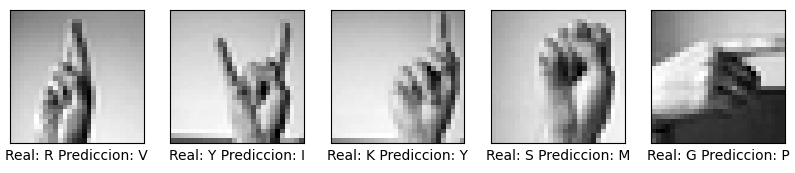

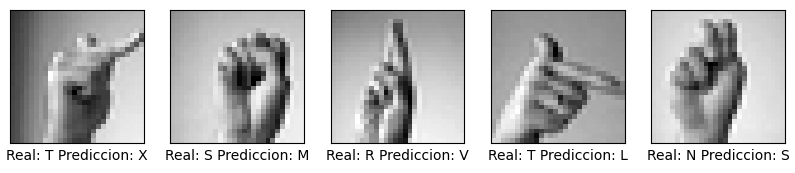

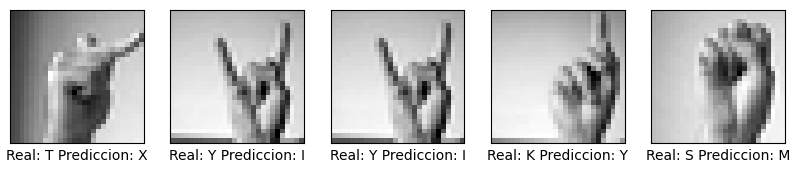

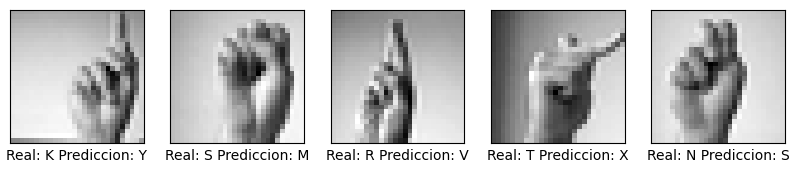

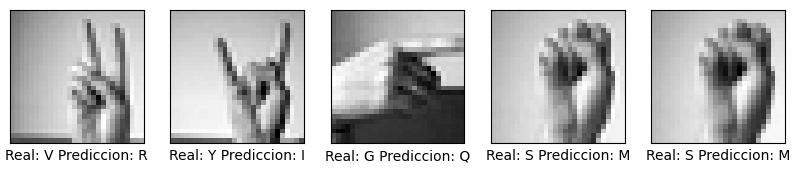

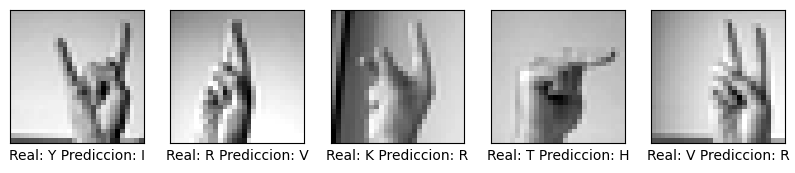

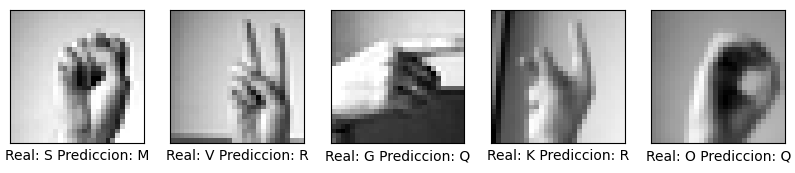

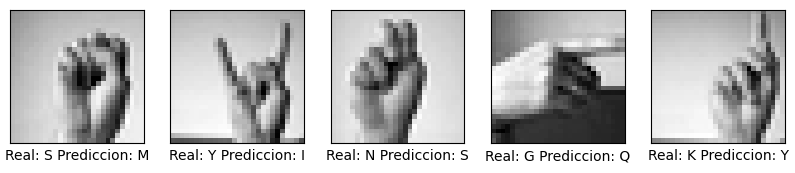

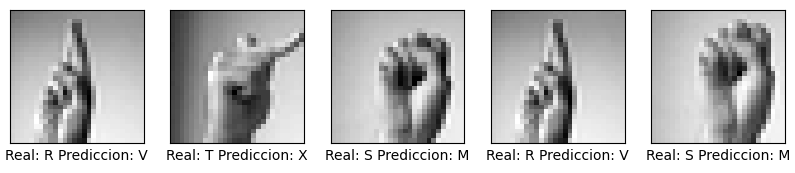

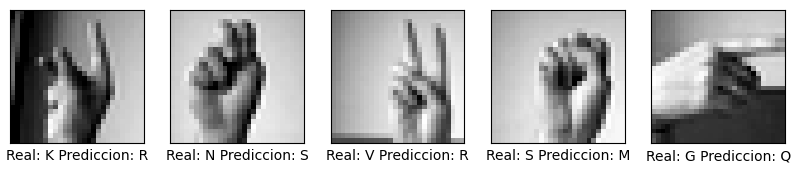

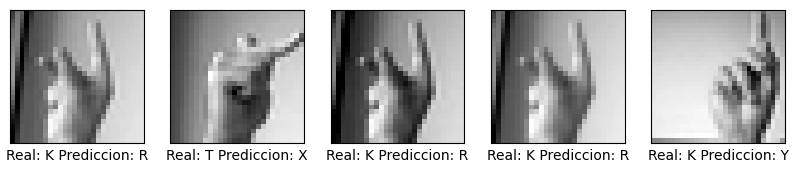

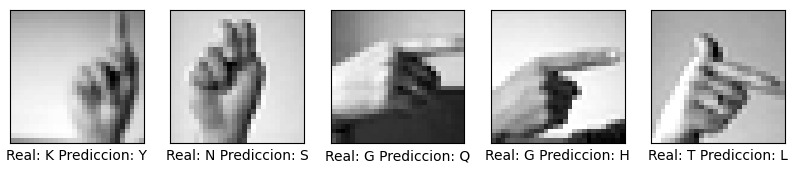

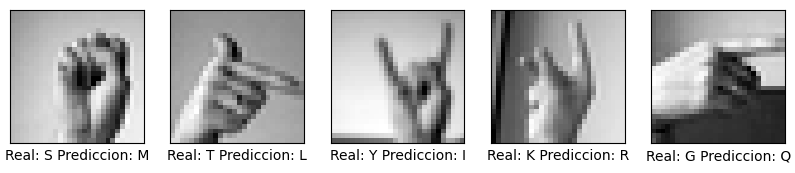

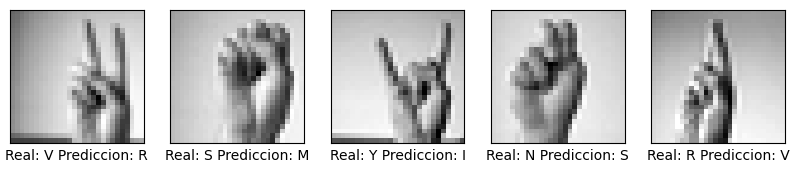

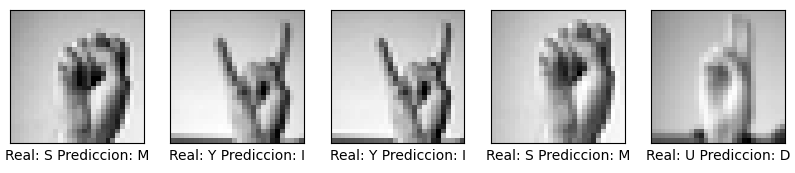

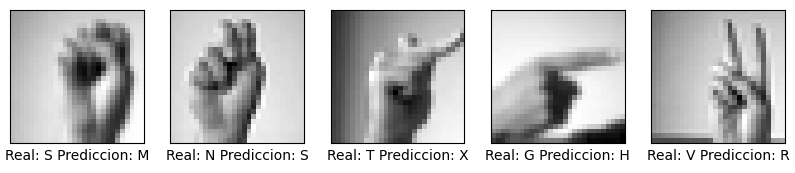

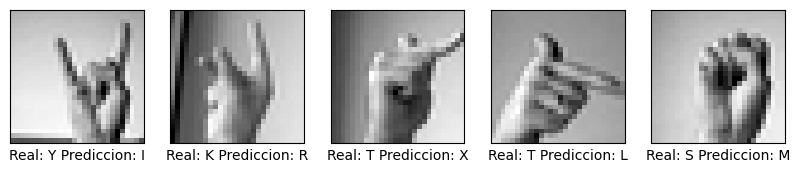

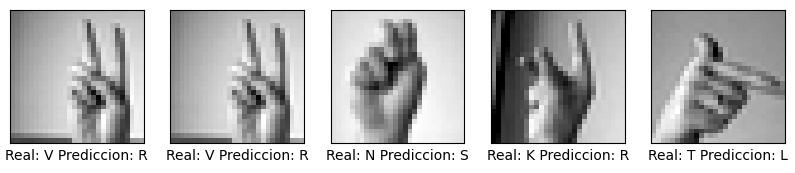

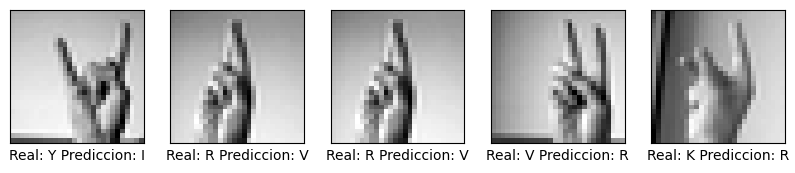

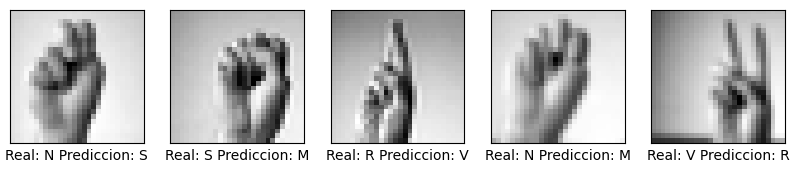

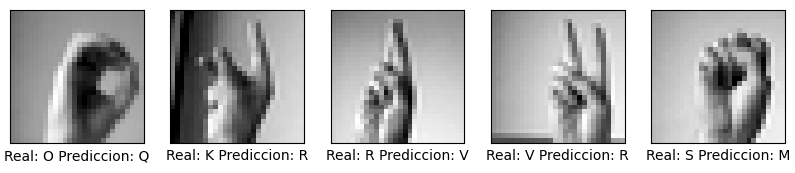

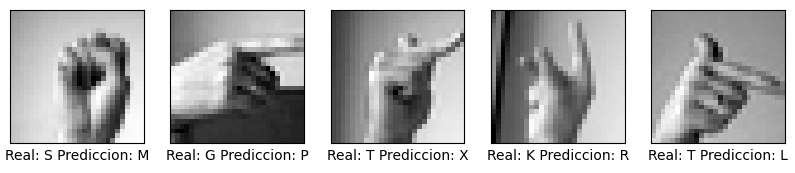

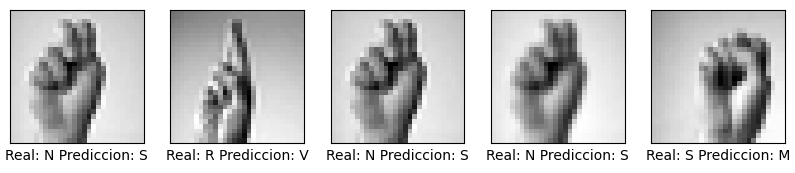

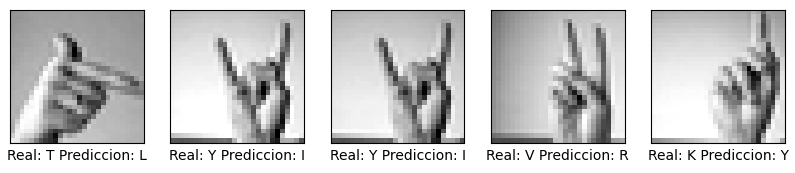

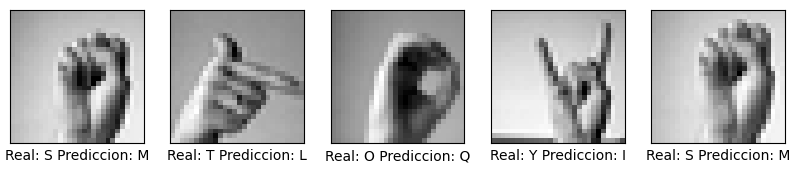

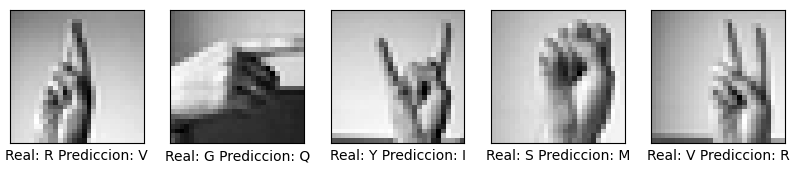

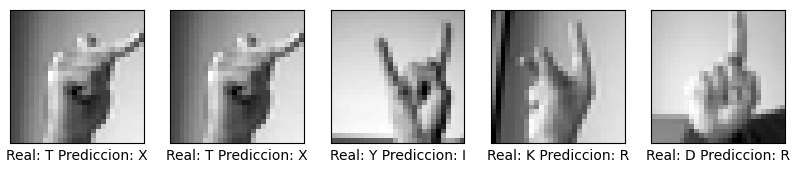

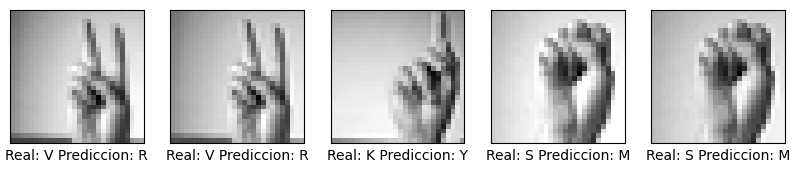

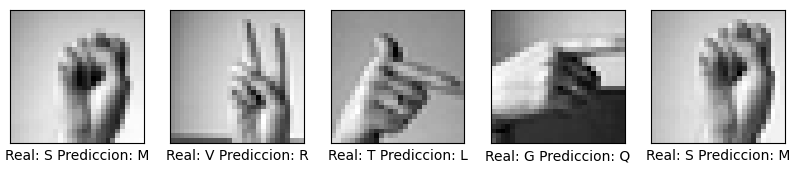

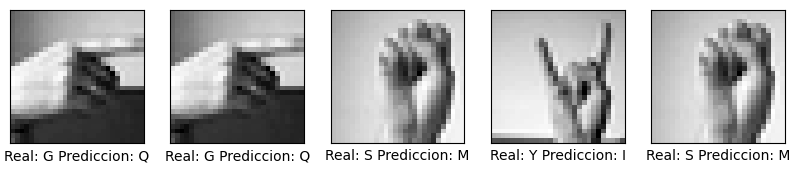

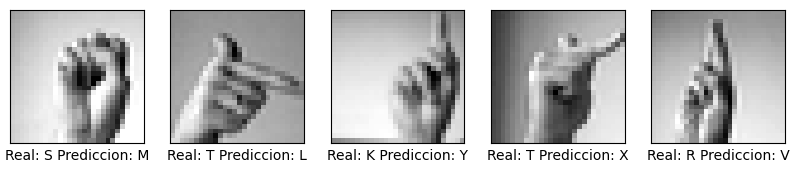

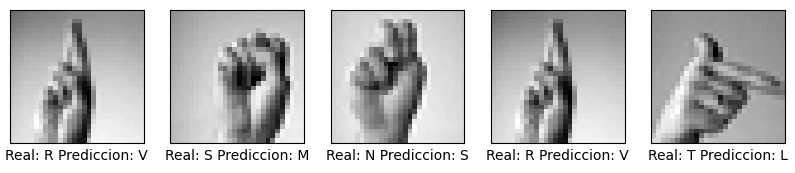

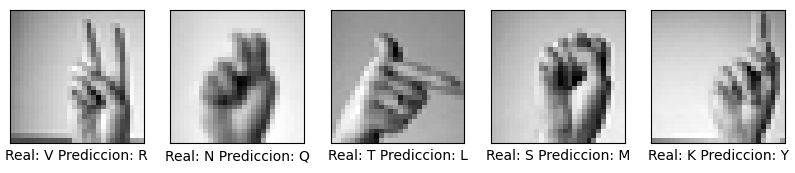

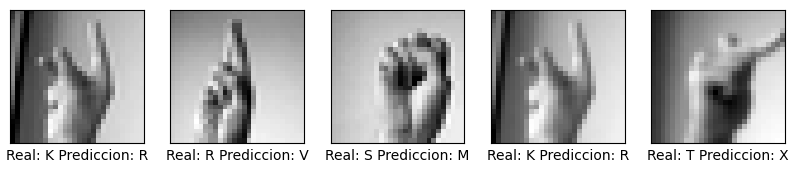

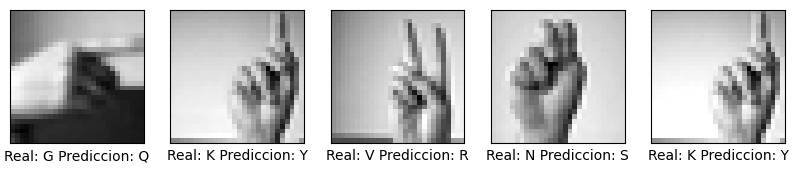

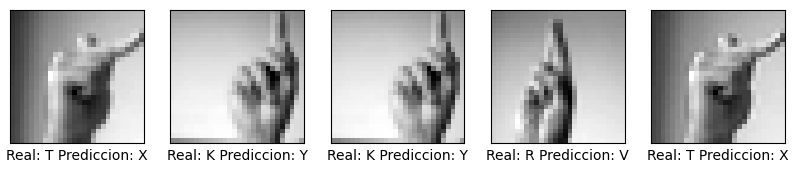

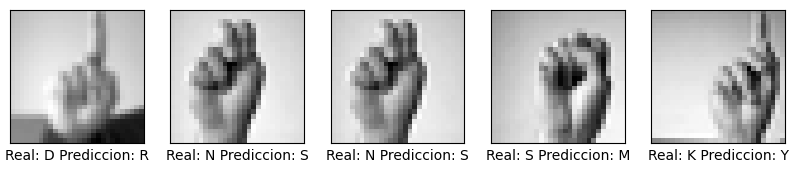

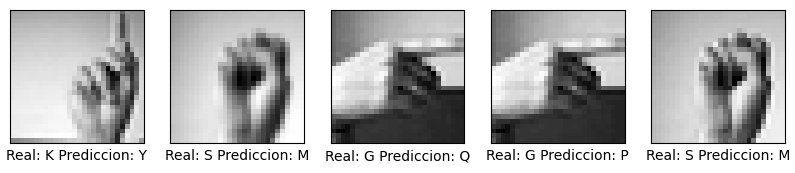

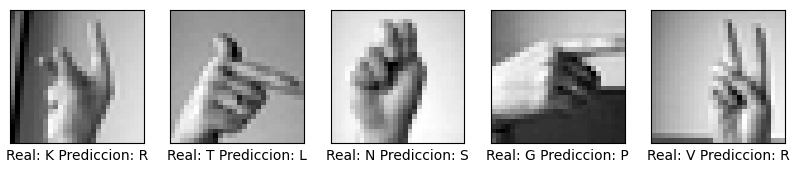

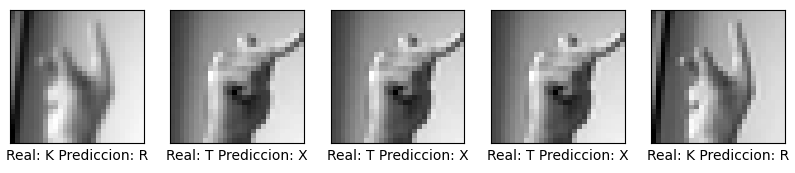

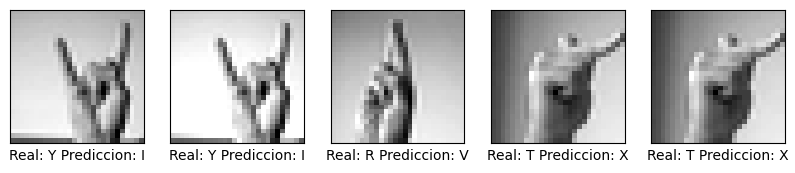

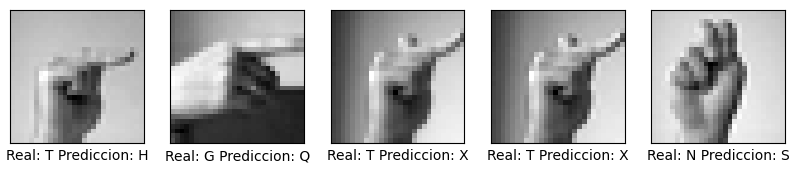

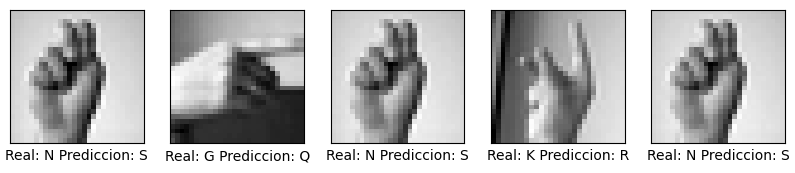

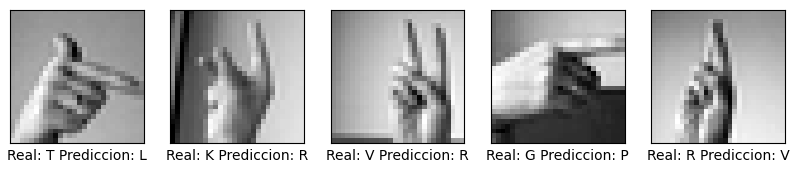

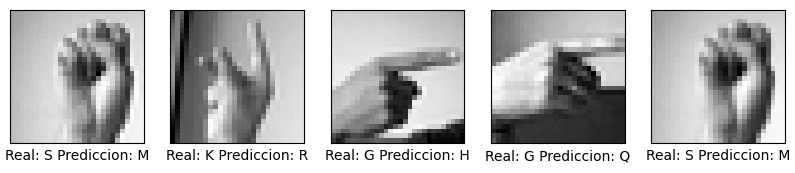

In [ ]:
errores = x_test[y_test != y_hat]
real_labels = y_test[y_test != y_hat]
predicted_labels = y_hat[y_test != y_hat]

for j in range(round(errores.shape[0]/5)):
    plt.figure(figsize=(10,10))
    for i in range(min(5,errores_count-5*j)):
        plt.subplot(1,min(5,errores_count-5*j),i+1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        number = errores[5*j+i].reshape(28,28)
        plt.imshow(number, cmap=plt.cm.gray)
        plt.xlabel("Real: {} Prediccion: {}".format
                   (abc[real_labels[5*j+i]],abc[predicted_labels[5*j+i]]))
    plt.show()

##**La Matriz de Confusión**

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [ ]:
mod_confusion_matrix = confusion_matrix(y_test, y_hat)
for i in range(24):
    mod_confusion_matrix[i][i] = 0

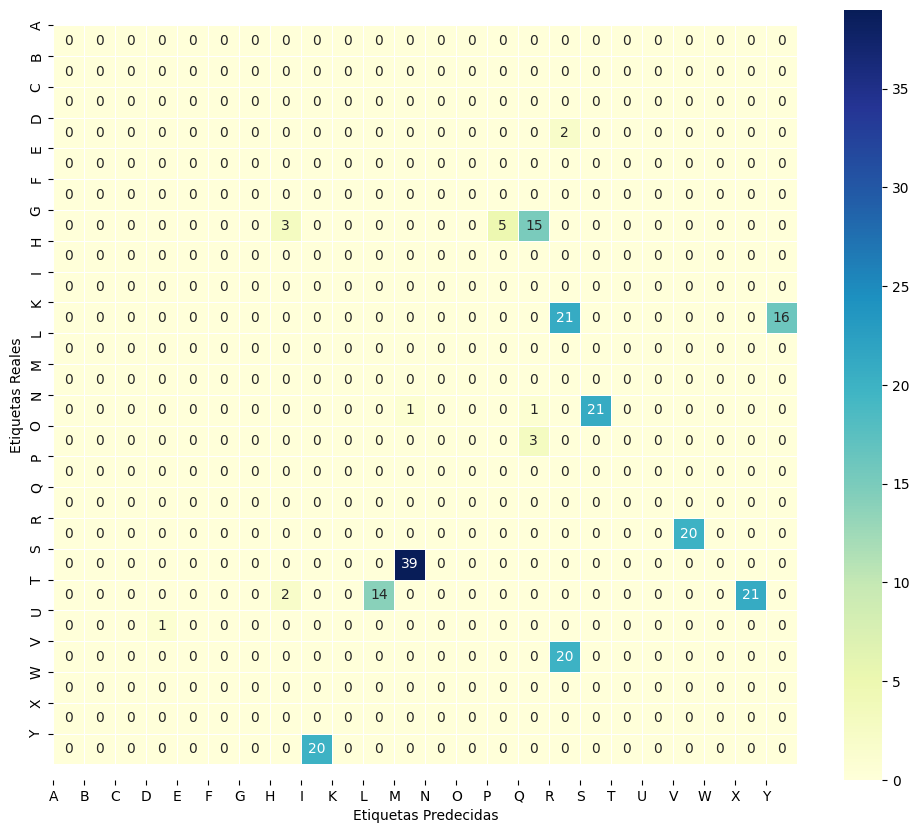

In [ ]:
fig = plt.figure(figsize=(12,10))
ax = fig.add_subplot(1,1,1)
sns.heatmap(mod_confusion_matrix, linewidth=0.5, annot=True, cmap="YlGnBu")
plt.xticks(np.arange(24), abc)
plt.yticks(np.arange(24), abc)
plt.ylabel("Etiquetas Reales")
plt.xlabel("Etiquetas Predecidas")
ax.set_ylim(24.5,-0.5);

##**GUARDANDO EL MODELO y DATOS ENTRENADOS**

In [ ]:
# model.save('/content/drive/MyDrive/Machine Learning/Models_saved/lenguaje_senhas_model.h5')
keras.saving.save_model(model, '/content/drive/MyDrive/Machine Learning/Models_saved/lenguaje_senhas_model.h5')

# Guardando los datos de entrenamiento y prueba
np.save('/content/drive/MyDrive/Machine Learning/Models_saved/lenguaje_senhas_x_train.npy', x_train)
np.save('/content/drive/MyDrive/Machine Learning/Models_saved/lenguaje_senhas_y_train.npy', y_train)

##**CARGANDO MODELOS GUARDADOS Y SUS DATOS**

In [ ]:
# Cargamos el modelo de red neuronal
model_senhias = tf.keras.models.load_model('/content/drive/MyDrive/Machine Learning/Models_saved/lenguaje_senhas_model.h5')

# Cargamos los datos
senhias_x_train = np.load('/content/drive/MyDrive/Machine Learning/Models_saved/lenguaje_senhas_x_train.npy')
senhias_y_train = np.load('/content/drive/MyDrive/Machine Learning/Models_saved/lenguaje_senhas_y_train.npy')